Conductor types:
  1 - Solid round
  2 - Stranded, 7 strands
  3 - Stranded, 19 strands
  4 - Stranded, 37 strands
  5 - ACSR 26/7


Select conductor type (1-5):  5
Enter physical radius of each conductor (m):  0.0141
Enter vertical spacing between phases A and B (m):  4.5
Enter vertical spacing between phases B and C (m):  4.5
Enter horizontal spacing between corresponding circuits (m):  8.0


,Parameter,Value
0,Conductor type,ACSR 26/7
1,Conductor radius (m),0.0141
2,Single-conductor GMR (m),0.011421
3,Phase spacing D_AB (m),4.5
4,Phase spacing D_BC (m),4.5
5,Phase spacing D_AC (m),9.0
6,Circuit spacing D_CC (m),8.0
7,Equivalent phase GMR (m),0.302271
8,Equivalent phase radius (m),0.335857
9,GMD_AB (m),6.426858


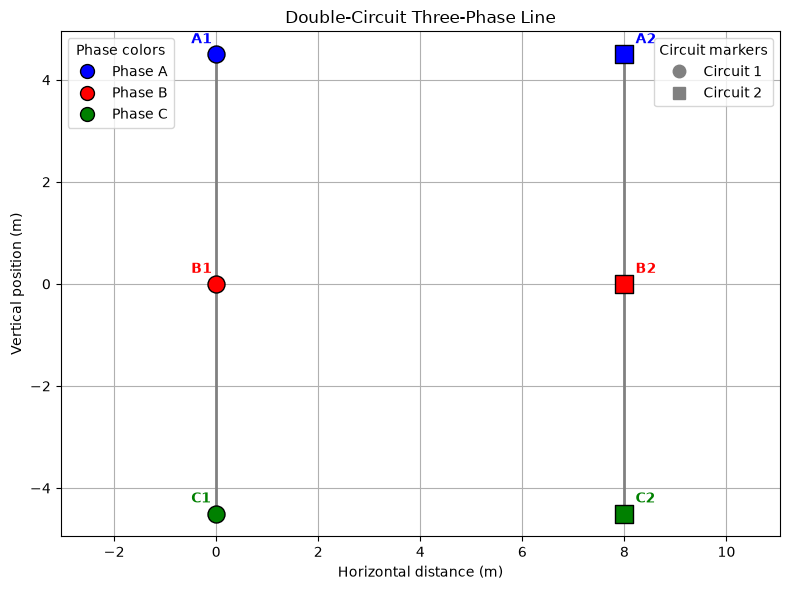

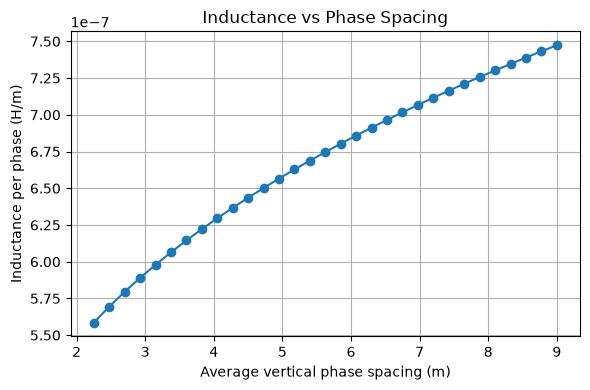

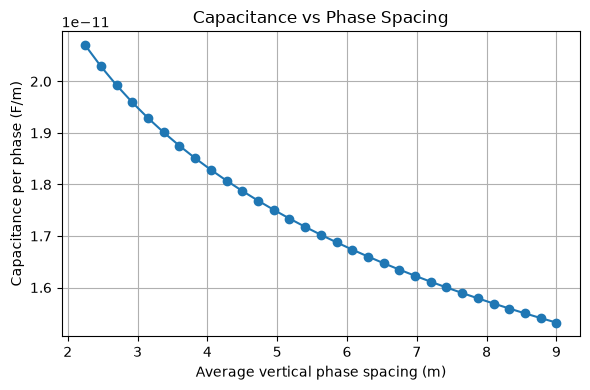

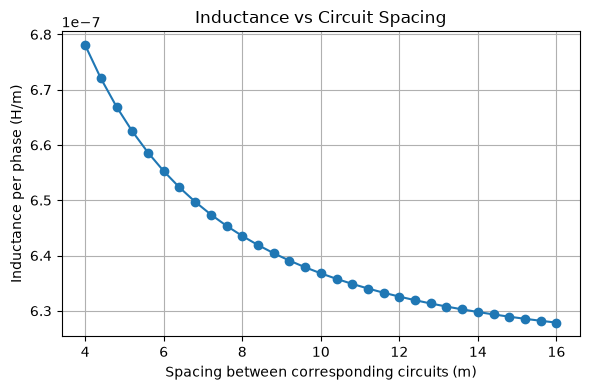

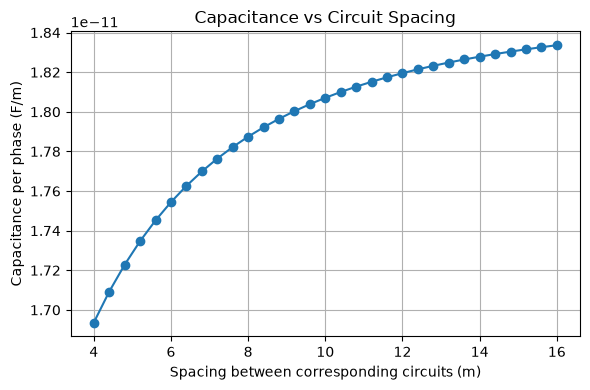


--- Conclusions ---
This model treats the two conductors carrying the same phase in the two circuits as one equivalent phase group.
Increasing phase spacing generally increases the overall GMD, which increases inductance and decreases capacitance.
Changing circuit spacing changes both the equivalent phase GMR and the mutual GMDs between phase groups.
The calculated inductance and capacitance are per phase per metre.


In [2]:
# ============================================================
# DOUBLE-CIRCUIT THREE-PHASE LINE WITH UNBUNDLED CONDUCTORS
# GMR, GMD, INDUCTANCE, CAPACITANCE AND GRAPHS
# ============================================================

import math
import matplotlib.pyplot as plt
import pandas as pd


# -------------------------
# 1. Conductor inputs
# -------------------------

conductor_types = {
    "1": ("Solid round", 0.7788),
    "2": ("Stranded, 7 strands", 0.726),
    "3": ("Stranded, 19 strands", 0.758),
    "4": ("Stranded, 37 strands", 0.768),
    "5": ("ACSR 26/7", 0.81),
}

print("Conductor types:")
for key, (name, _) in conductor_types.items():
    print(f"  {key} - {name}")

choice = input("Select conductor type (1-5): ").strip()
while choice not in conductor_types:
    choice = input("Invalid choice. Select conductor type (1-5): ").strip()

conductor_name, gmr_factor = conductor_types[choice]

r = float(input("Enter physical radius of each conductor (m): "))
if r <= 0:
    raise ValueError("Conductor radius must be greater than zero.")

# GMR of one conductor
GMR_single = gmr_factor * r


# -------------------------
# 2. Line geometry inputs
# -------------------------

D_AB = float(input("Enter vertical spacing between phases A and B (m): "))
D_BC = float(input("Enter vertical spacing between phases B and C (m): "))
D_CC = float(input("Enter horizontal spacing between corresponding circuits (m): "))

if min(D_AB, D_BC, D_CC) <= 0:
    raise ValueError("All phase and circuit spacings must be greater than zero.")

# Free-space permittivity
epsilon_0 = 8.854e-12


# -------------------------
# 3. Geometry and parameter functions
# -------------------------

def line_positions(D_AB, D_BC, D_CC):
    """
    Return conductor coordinates for two side-by-side circuits.

    Circuit 1 is at x = 0.
    Circuit 2 is at x = D_CC.
    Phases A, B, C are vertically arranged in that order.
    """

    y_positions = {
        "A": D_BC,
        "B": 0.0,
        "C": -D_AB,
    }

    circuit_1 = {
        phase: (0.0, y)
        for phase, y in y_positions.items()
    }
    circuit_2 = {
        phase: (D_CC, y)
        for phase, y in y_positions.items()
    }

    return circuit_1, circuit_2


def point_distance(point_1, point_2):
    """Calculate distance between two (x, y) points."""

    return math.hypot(
        point_1[0] - point_2[0],
        point_1[1] - point_2[1]
    )


def phase_group_gmd(phase_1_positions, phase_2_positions):
    """
    Calculate the GMD between two phase groups.
    Each phase group contains one conductor in each circuit.
    """

    distances = [
        point_distance(p1, p2)
        for p1 in phase_1_positions
        for p2 in phase_2_positions
    ]

    return math.prod(distances) ** (1 / len(distances))


def calculate_line_parameters(D_AB, D_BC, D_CC):
    """Calculate double-circuit equivalent GMR, GMD, L and C."""

    circuit_1, circuit_2 = line_positions(D_AB, D_BC, D_CC)

    phase_positions = {
        "A": [circuit_1["A"], circuit_2["A"]],
        "B": [circuit_1["B"], circuit_2["B"]],
        "C": [circuit_1["C"], circuit_2["C"]],
    }

    # Equivalent self GMR and radius for each two-conductor phase group.
    # The two same-phase conductors are separated by D_CC.
    GMR_phase = math.sqrt(GMR_single * D_CC)
    radius_phase = math.sqrt(r * D_CC)

    # Mutual GMDs between phase groups
    GMD_AB = phase_group_gmd(
        phase_positions["A"], phase_positions["B"]
    )
    GMD_BC = phase_group_gmd(
        phase_positions["B"], phase_positions["C"]
    )
    GMD_CA = phase_group_gmd(
        phase_positions["C"], phase_positions["A"]
    )

    # Overall GMD for the transposed three-phase line
    GMD_overall = (GMD_AB * GMD_BC * GMD_CA) ** (1 / 3)

    if GMD_overall <= GMR_phase:
        raise ValueError(
            "Overall GMD must be greater than the equivalent phase GMR."
        )
    if GMD_overall <= radius_phase:
        raise ValueError(
            "Overall GMD must be greater than the equivalent phase radius."
        )

    # Inductance per phase per metre (H/m)
    inductance = 2e-7 * math.log(GMD_overall / GMR_phase)

    # Capacitance per phase per metre (F/m)
    capacitance = (
        2 * math.pi * epsilon_0
        / math.log(GMD_overall / radius_phase)
    )

    return {
        "GMR_phase": GMR_phase,
        "radius_phase": radius_phase,
        "GMD_AB": GMD_AB,
        "GMD_BC": GMD_BC,
        "GMD_CA": GMD_CA,
        "GMD_overall": GMD_overall,
        "inductance": inductance,
        "capacitance": capacitance,
    }


# Calculate parameters for the entered geometry
results = calculate_line_parameters(D_AB, D_BC, D_CC)


# -------------------------
# 4. Display results
# -------------------------

summary = pd.DataFrame({
    "Parameter": [
        "Conductor type",
        "Conductor radius (m)",
        "Single-conductor GMR (m)",
        "Phase spacing D_AB (m)",
        "Phase spacing D_BC (m)",
        "Phase spacing D_AC (m)",
        "Circuit spacing D_CC (m)",
        "Equivalent phase GMR (m)",
        "Equivalent phase radius (m)",
        "GMD_AB (m)",
        "GMD_BC (m)",
        "GMD_CA (m)",
        "Overall GMD (m)",
        "Inductance per phase (H/m)",
        "Capacitance per phase (F/m)",
    ],
    "Value": [
        conductor_name,
        r,
        GMR_single,
        D_AB,
        D_BC,
        D_AB + D_BC,
        D_CC,
        results["GMR_phase"],
        results["radius_phase"],
        results["GMD_AB"],
        results["GMD_BC"],
        results["GMD_CA"],
        results["GMD_overall"],
        results["inductance"],
        results["capacitance"],
    ],
})

display(summary)


# -------------------------
# 5. Plot double-circuit layout
# -------------------------

circuit_1, circuit_2 = line_positions(D_AB, D_BC, D_CC)

phase_colors = {
    "A": "blue",
    "B": "red",
    "C": "green",
}

plt.figure(figsize=(8, 6))

for phase in ["A", "B", "C"]:
    x1, y1 = circuit_1[phase]
    x2, y2 = circuit_2[phase]
    color = phase_colors[phase]

    # Circuit 1 uses circles
    plt.scatter(
        x1, y1,
        color=color,
        marker="o",
        s=150,
        edgecolors="black",
        label=f"Phase {phase}" if phase == "A" else None,
        zorder=3
    )

    # Circuit 2 uses squares
    plt.scatter(
        x2, y2,
        color=color,
        marker="s",
        s=150,
        edgecolors="black",
        zorder=3
    )

    plt.annotate(
        f"{phase}1",
        (x1, y1),
        xytext=(-18, 8),
        textcoords="offset points",
        color=color,
        fontweight="bold"
    )

    plt.annotate(
        f"{phase}2",
        (x2, y2),
        xytext=(8, 8),
        textcoords="offset points",
        color=color,
        fontweight="bold"
    )

# Draw the two support columns
plt.plot(
    [0, 0],
    [-D_AB, D_BC],
    color="gray",
    linewidth=2
)
plt.plot(
    [D_CC, D_CC],
    [-D_AB, D_BC],
    color="gray",
    linewidth=2
)

plt.title("Double-Circuit Three-Phase Line")
plt.xlabel("Horizontal distance (m)")
plt.ylabel("Vertical position (m)")
plt.grid(True)
plt.axis("equal")

# Legend for phase colors and circuit markers
phase_legend = [
    plt.Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=phase_colors[p],
        markeredgecolor="black",
        label=f"Phase {p}",
        markersize=10
    )
    for p in ["A", "B", "C"]
]

circuit_legend = [
    plt.Line2D(
        [0], [0],
        marker="o",
        color="gray",
        linestyle="None",
        label="Circuit 1",
        markersize=9
    ),
    plt.Line2D(
        [0], [0],
        marker="s",
        color="gray",
        linestyle="None",
        label="Circuit 2",
        markersize=9
    ),
]

legend_1 = plt.legend(
    handles=phase_legend,
    title="Phase colors",
    loc="upper left"
)
plt.gca().add_artist(legend_1)
plt.legend(
    handles=circuit_legend,
    title="Circuit markers",
    loc="upper right"
)

plt.tight_layout()
plt.show()


# -------------------------
# 6. Plot inductance and capacitance
#    versus phase spacing
# -------------------------

# Scale both vertical phase spacings proportionally.
# This preserves the entered phase arrangement.
phase_factors = [0.5 + 0.05 * i for i in range(31)]

phase_spacing_values = []
phase_inductances = []
phase_capacitances = []

for factor in phase_factors:
    D_AB_var = D_AB * factor
    D_BC_var = D_BC * factor

    try:
        values = calculate_line_parameters(
            D_AB_var,
            D_BC_var,
            D_CC
        )
        phase_spacing_values.append(
            (D_AB_var + D_BC_var) / 2
        )
        phase_inductances.append(values["inductance"])
        phase_capacitances.append(values["capacitance"])
    except ValueError:
        # Skip invalid points where the logarithm would not be valid.
        continue

plt.figure(figsize=(6, 4))
plt.plot(phase_spacing_values, phase_inductances, marker="o")
plt.title("Inductance vs Phase Spacing")
plt.xlabel("Average vertical phase spacing (m)")
plt.ylabel("Inductance per phase (H/m)")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(phase_spacing_values, phase_capacitances, marker="o")
plt.title("Capacitance vs Phase Spacing")
plt.xlabel("Average vertical phase spacing (m)")
plt.ylabel("Capacitance per phase (F/m)")
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------
# 7. Plot inductance and capacitance
#    versus circuit spacing
# -------------------------

# Vary circuit spacing around the entered value.
circuit_factors = [0.5 + 0.05 * i for i in range(31)]

circuit_spacing_values = []
circuit_inductances = []
circuit_capacitances = []

for factor in circuit_factors:
    D_CC_var = D_CC * factor

    try:
        values = calculate_line_parameters(
            D_AB,
            D_BC,
            D_CC_var
        )
        circuit_spacing_values.append(D_CC_var)
        circuit_inductances.append(values["inductance"])
        circuit_capacitances.append(values["capacitance"])
    except ValueError:
        # Skip invalid points where the logarithm would not be valid.
        continue

plt.figure(figsize=(6, 4))
plt.plot(circuit_spacing_values, circuit_inductances, marker="o")
plt.title("Inductance vs Circuit Spacing")
plt.xlabel("Spacing between corresponding circuits (m)")
plt.ylabel("Inductance per phase (H/m)")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(circuit_spacing_values, circuit_capacitances, marker="o")
plt.title("Capacitance vs Circuit Spacing")
plt.xlabel("Spacing between corresponding circuits (m)")
plt.ylabel("Capacitance per phase (F/m)")
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------
# 8. Conclusions
# -------------------------

print("\n--- Conclusions ---")
print(
    "This model treats the two conductors carrying the same phase "
    "in the two circuits as one equivalent phase group."
)
print(
    "Increasing phase spacing generally increases the overall GMD, "
    "which increases inductance and decreases capacitance."
)
print(
    "Changing circuit spacing changes both the equivalent phase GMR "
    "and the mutual GMDs between phase groups."
)
print(
    "The calculated inductance and capacitance are per phase per metre."
)